In [ ]:
#SHAP Analysis for KRFP

Fitting 5 folds for each of 216 candidates, totalling 1080 fits
Accuracy: 0.8382352941176471
Macro Precision: 0.8532785256002945
Macro Recall: 0.7975373482726424
Macro F1: 0.8190769332426923
Weighted Precision: 0.8430719174675354
Weighted Recall: 0.8382352941176471
Weighted F1: 0.8347164771448639
Balanced Accuracy: 0.7975373482726424
Log Loss: 0.4714324415634469


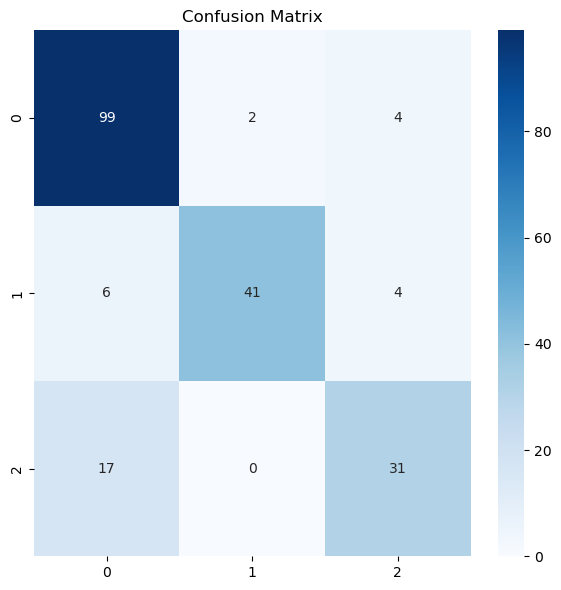

In [7]:
#RF Model
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score,recall_score, f1_score,confusion_matrix,balanced_accuracy_score,log_loss)

df = pd.read_excel("KRFP_CYP17_SHAP.xlsx")
X = df.drop("Name", axis=1)
y_cat = df["Name"].astype("category")
y = y_cat.cat.codes.values
class_names = y_cat.cat.categories

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
feature_names = X.columns

# Random Forest + GridSearchCV

param_grid = {
    "n_estimators": [200, 300, 500],
    "max_depth": [None, 10, 20, 30],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2"]}

rf = RandomForestClassifier(random_state=42, n_jobs=-1)

grid = GridSearchCV( estimator=rf, param_grid=param_grid, scoring="f1_weighted", cv=5, n_jobs=-1, verbose=1)

grid.fit(X_train, y_train)

model = grid.best_estimator_
y_pred = model.predict(X_test)

# Evaluation
y_pred = model.predict(X_test)
y_pred_proba = model.predict_proba(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Macro Precision:", precision_score(y_test, y_pred, average="macro"))
print("Macro Recall:", recall_score(y_test, y_pred, average="macro"))
print("Macro F1:", f1_score(y_test, y_pred, average="macro"))
print("Weighted Precision:", precision_score(y_test, y_pred, average="weighted"))
print("Weighted Recall:", recall_score(y_test, y_pred, average="weighted"))
print("Weighted F1:", f1_score(y_test, y_pred, average="weighted"))
print("Balanced Accuracy:", balanced_accuracy_score(y_test, y_pred))
print("Log Loss:", log_loss(y_test, y_pred_proba))

plt.figure(figsize=(6, 6))
sns.heatmap(
    confusion_matrix(y_test, y_pred),
    annot=True, fmt="d", cmap="Blues",
    xticklabels=class_names, yticklabels=class_names)
plt.title("Confusion Matrix")
plt.tight_layout()
plt.savefig('Confusion_matrix_CSFB.png', format='png', dpi=600)
plt.show()

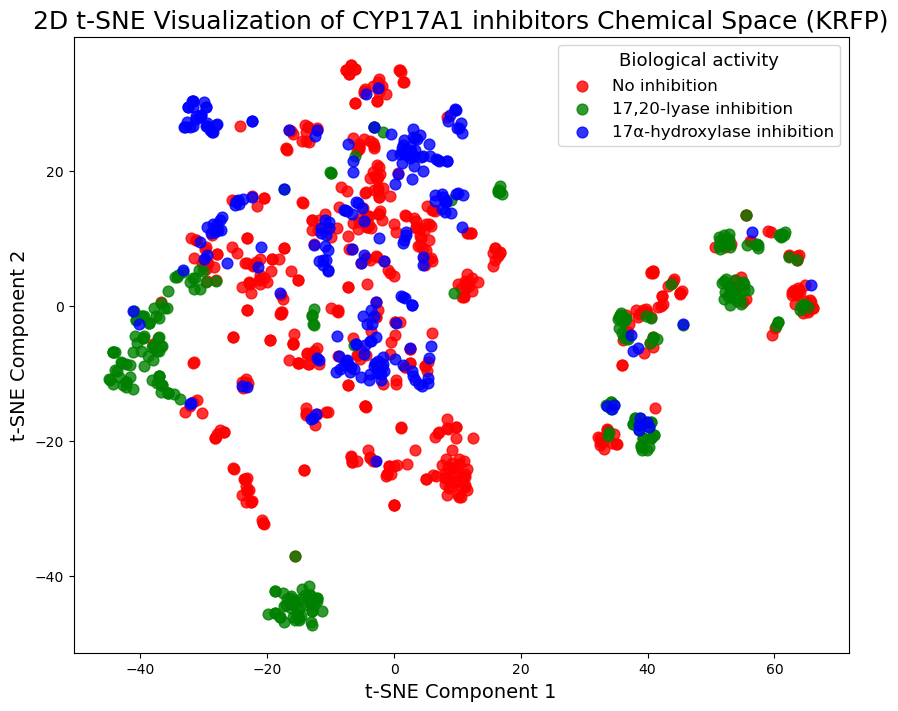

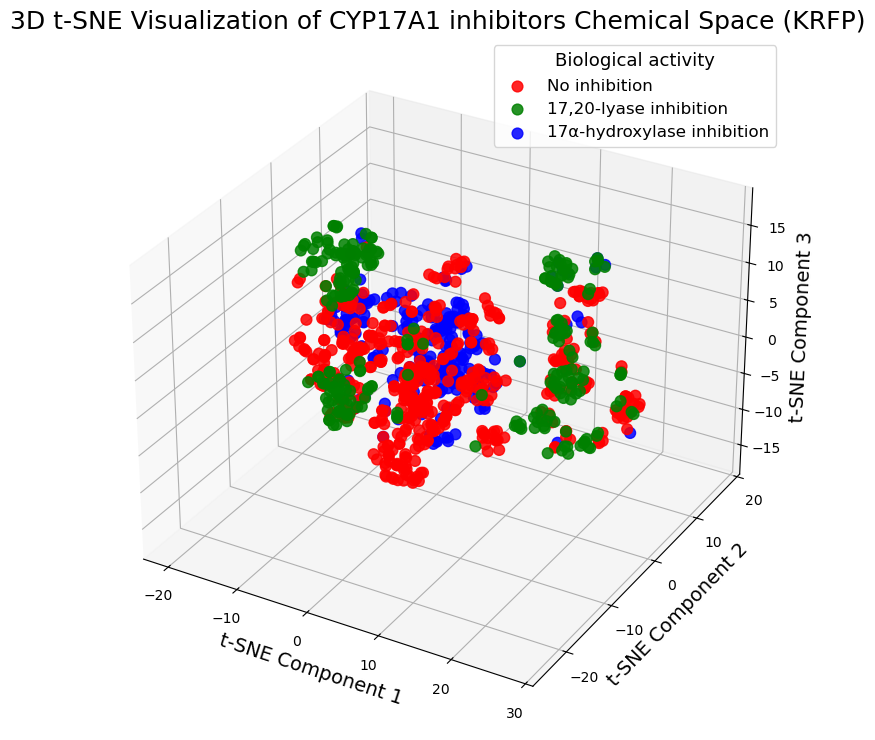

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE

df = pd.read_excel('KRFP_CYP17_SHAP.xlsx')
X = df.drop('Name', axis=1)
y = df['Name']
class_map = { 0: "No inhibition", 1: "17,20-lyase inhibition", 2: "17α-hydroxylase inhibition"}

y_named = y.map(class_map)

# 2D graph
tsne_2d = TSNE(n_components=2, random_state=42)
X_tsne_2d = tsne_2d.fit_transform(X)

colors = {
    "No inhibition": "red",
    "17,20-lyase inhibition": "green",
    "17α-hydroxylase inhibition": "blue"}

plt.figure(figsize=(10, 8))

for cls in class_map.values():
    mask = (y_named == cls)
    plt.scatter(
        X_tsne_2d[mask, 0],
        X_tsne_2d[mask, 1],
        s=60,
        alpha=0.8,
        label=cls,
        color=colors[cls])

plt.title("2D t-SNE Visualization of CYP17A1 inhibitors Chemical Space (KRFP)", fontsize=18)
plt.xlabel("t-SNE Component 1", fontsize=14)
plt.ylabel("t-SNE Component 2", fontsize=14)
plt.legend(title="Biological activity", fontsize=12, title_fontsize=13)
plt.grid(False)
plt.savefig("tsne_2D_chemical_space_matplotlib.png", dpi=600, bbox_inches="tight")
plt.show()


# 3D graph
tsne_3d = TSNE(n_components=3, random_state=42)
X_tsne_3d = tsne_3d.fit_transform(X)
fig = plt.figure(figsize=(12, 9))
ax = fig.add_subplot(111, projection='3d')

for cls in class_map.values():
    mask = (y_named == cls)
    ax.scatter(
        X_tsne_3d[mask, 0],
        X_tsne_3d[mask, 1],
        X_tsne_3d[mask, 2],
        s=60,
        alpha=0.85,
        label=cls,
        color=colors[cls])

ax.set_title("3D t-SNE Visualization of CYP17A1 inhibitors Chemical Space (KRFP)", fontsize=18)
ax.set_xlabel("t-SNE Component 1", fontsize=14)
ax.set_ylabel("t-SNE Component 2", fontsize=14)
ax.set_zlabel("t-SNE Component 3", fontsize=14)

ax.legend(title="Biological activity", fontsize=12, title_fontsize=13)

plt.savefig("tsne_3D_chemical_space_matplotlib.png", dpi=600, bbox_inches="tight")
plt.show()

In [6]:
import shap
# get shap values
explainer = shap.TreeExplainer(model)
shap_values = explainer(X_test) 

In [23]:
print(np.shape(shap_values))

(204, 4860, 3)


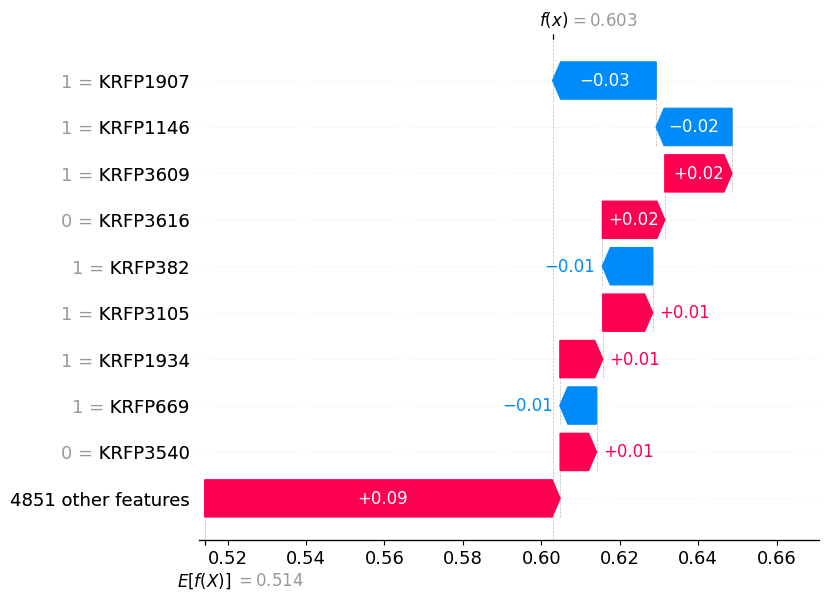

In [27]:
# waterfall plot 
shap.plots.waterfall(shap_values[0, :, 0])

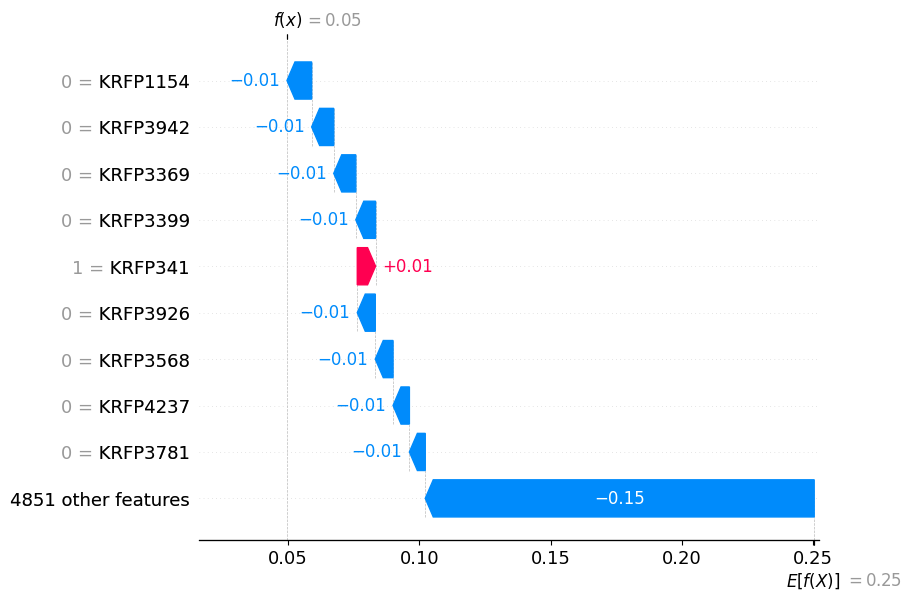

In [13]:
shap.plots.waterfall(shap_values[0, :, 1])

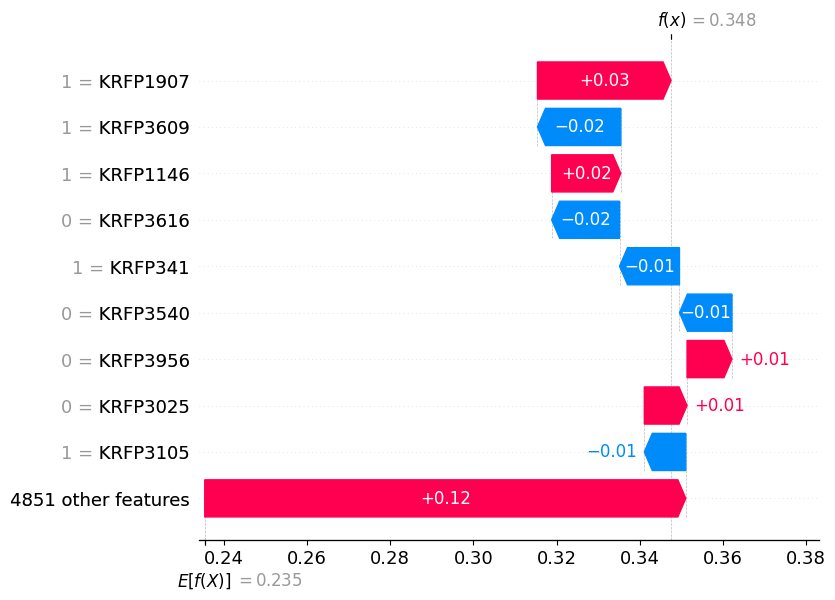

In [15]:
shap.plots.waterfall(shap_values[0, :, 2])

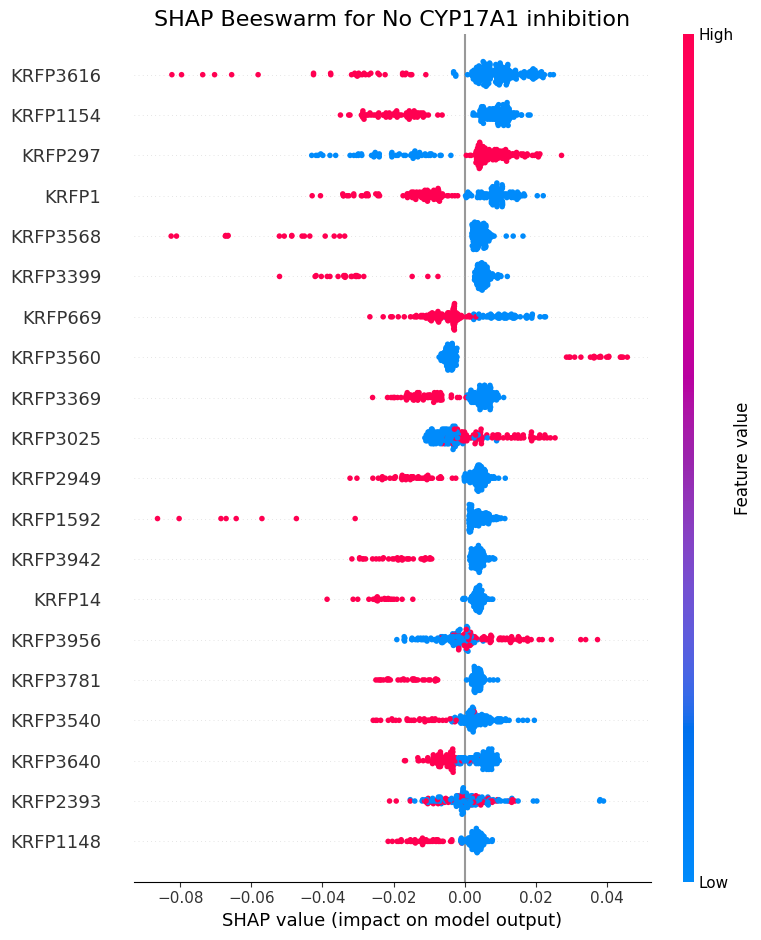

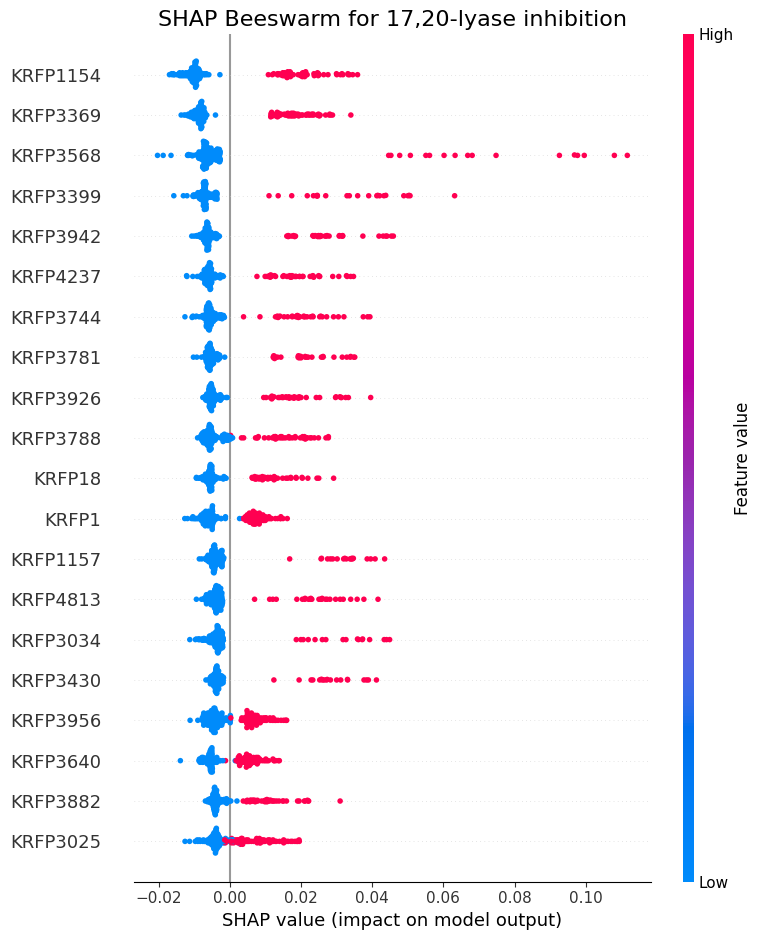

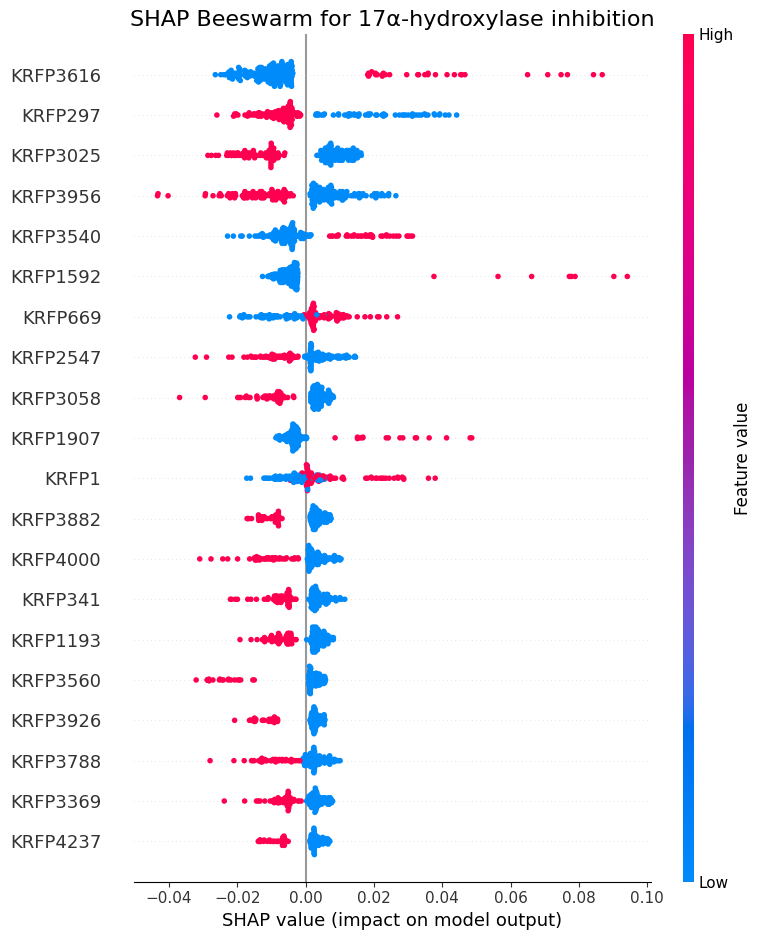

In [51]:
import matplotlib.pyplot as plt
import shap

class_names = {
    0: "No CYP17A1 inhibition",
    1: "17,20-lyase inhibition",
    2: "17α-hydroxylase inhibition"}

for i, cls in class_names.items():
    plt.figure(figsize=(10, 6))

    plt.title(f"SHAP Beeswarm for {cls}", fontsize=16)
    shap.summary_plot(
        shap_values.values[:, :, i],
        X_test,
        feature_names=feature_names,
        show=False)

    plt.savefig(
        f"shap_beeswarm_class_{i}.png",
        dpi=600,
        bbox_inches="tight")

    plt.show()
    plt.close()


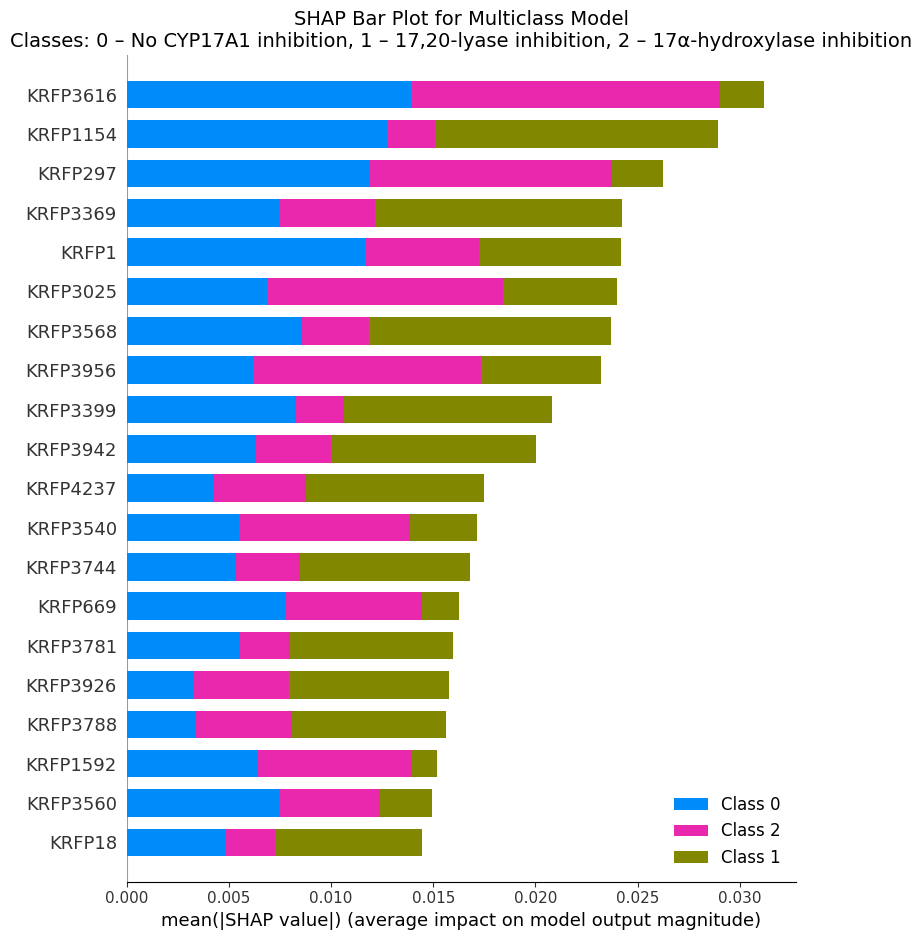

In [63]:
import matplotlib.pyplot as plt
import shap

class_names = { 0: "No CYP17A1 inhibition", 1: "17,20-lyase inhibition", 2: "17α-hydroxylase inhibition"}

class_title = ", ".join([f"{k} – {v}" for k, v in class_names.items()])

plt.figure(figsize=(10, 6))

plt.title(f"SHAP Bar Plot for Multiclass Model\nClasses: {class_title}", fontsize=14)

shap.summary_plot(
    shap_values,
    X_test,
    feature_names=feature_names,
    plot_type="bar",
    max_display=20,
    show=False)

plt.savefig("shap_bar_multiclass.png", dpi=600, bbox_inches="tight")
plt.show()

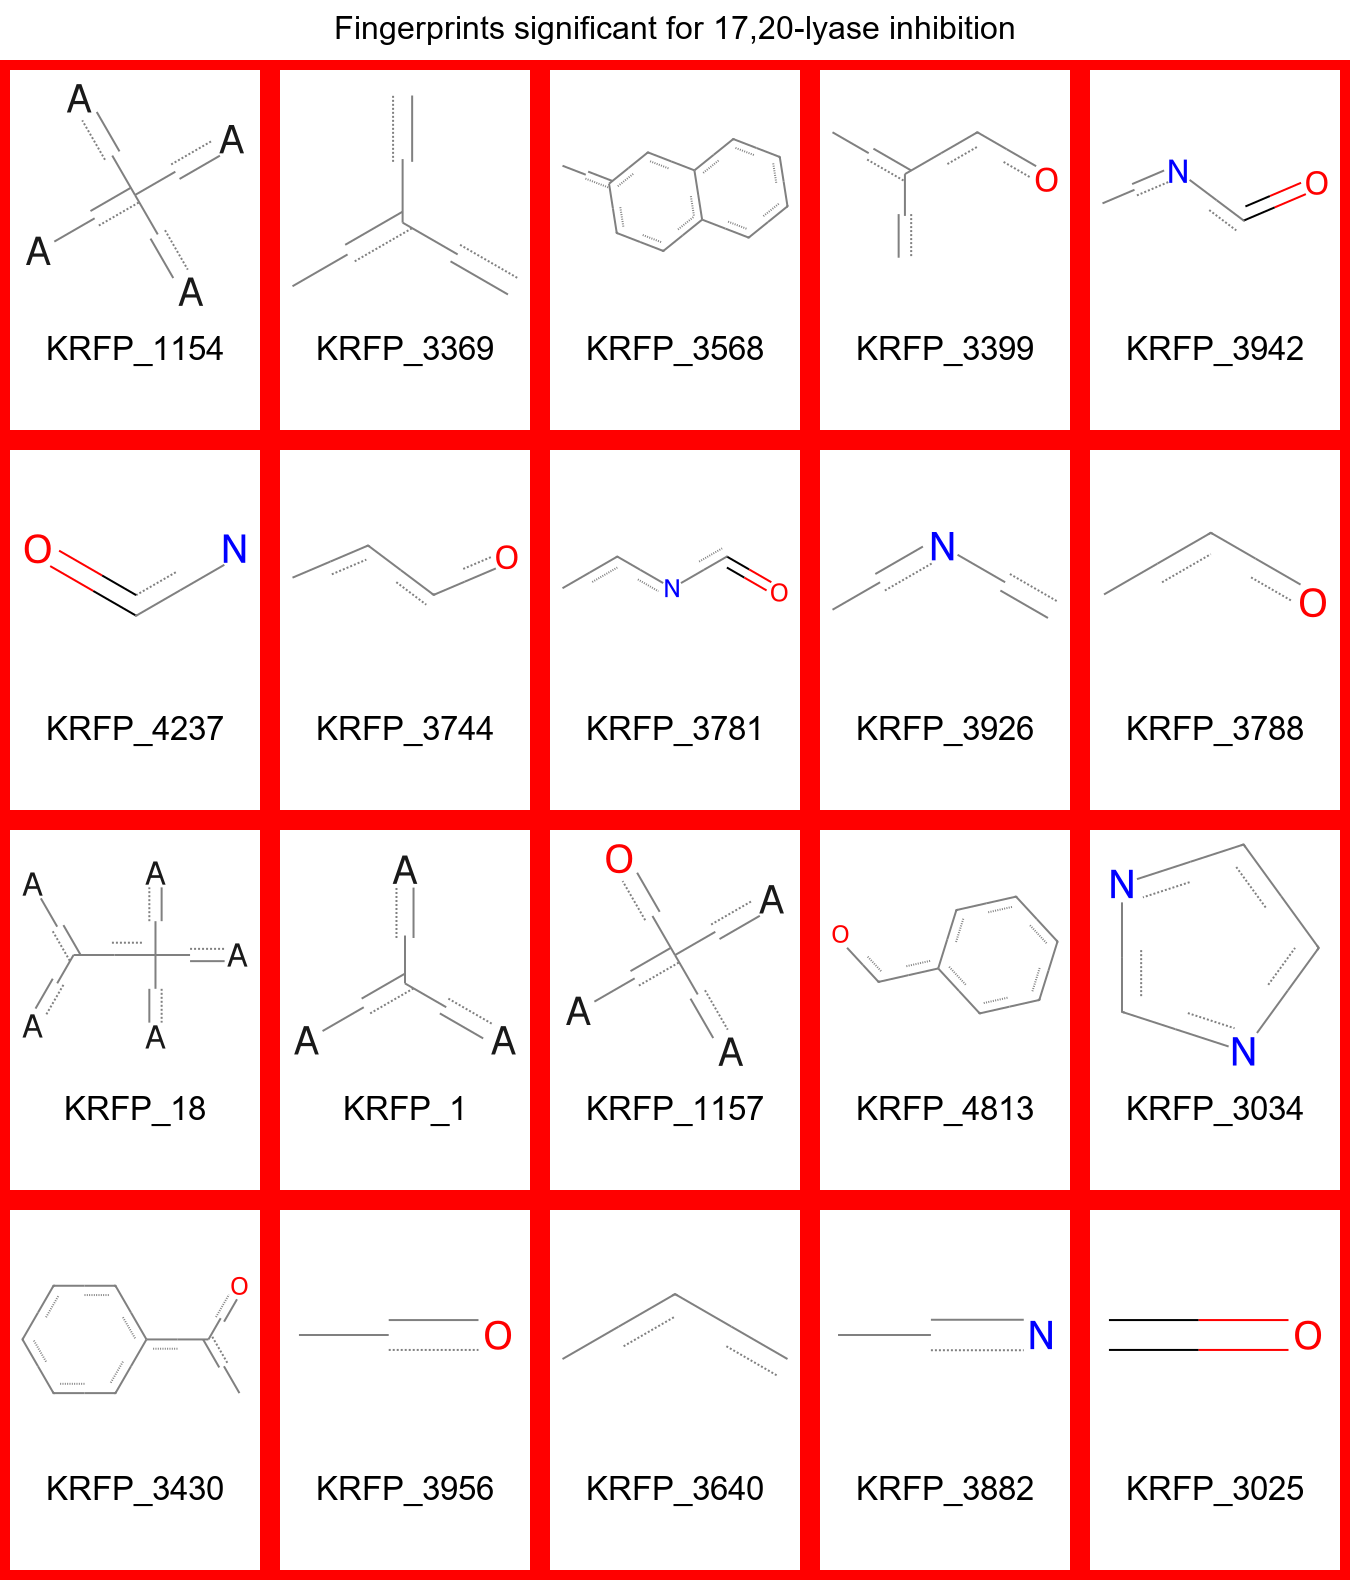

In [10]:
#LYASE ACTIVITY KRFP
import io
import math
import json
import re
from PIL import Image, ImageOps, ImageDraw, ImageFont
from rdkit import Chem
from rdkit.Chem.Draw import rdMolDraw2D

with open("krfp.json", "r") as f:
    raw_dict = json.load(f)
krfp_dict = {
    int(re.sub(r'\D', '', k)): v for k, v in raw_dict.items()}

selected_keys = [  1154, 3369, 3568, 3399, 3942,4237, 3744, 3781, 3926, 3788, 18,  1, 1157, 4813, 3034,3430, 3956, 3640, 3882, 3025]

red_keys = {1154, 3369, 3568, 3399, 3942,4237, 3744, 3781, 3926, 3788, 18, 1, 1157, 4813, 3034, 3430, 3956, 3640, 3882, 3025}

blue_keys = set(selected_keys) - red_keys

def draw_fragment(smarts, title, border_color, size=(250, 360), border_width=10):
    mol_height = size[0]
    total_width = size[0]
    total_height = size[1]

    mol = Chem.MolFromSmarts(smarts)
    if mol is None:
        mol = Chem.MolFromSmarts("[H]")
    drawer = rdMolDraw2D.MolDraw2DCairo(total_width, mol_height)
    rdMolDraw2D.PrepareAndDrawMolecule(drawer, mol)
    drawer.FinishDrawing()
    mol_png = drawer.GetDrawingText()
    mol_img = Image.open(io.BytesIO(mol_png)).convert("RGB")
    final_img = Image.new("RGB", (total_width, total_height), "white")
    final_img.paste(mol_img, (0, 0))

    draw = ImageDraw.Draw(final_img)
    try:
        font = ImageFont.truetype("arial.ttf", 33)
    except:
        font = ImageFont.load_default()
    bbox = draw.textbbox((0, 0), title, font=font)
    text_w = bbox[2] - bbox[0]
    x_center = (total_width - text_w) // 2
    draw.text((x_center, mol_height + 10), title, fill="black", font=font)
    final_img = ImageOps.expand(final_img, border=border_width, fill=border_color)
    return final_img

images = []
for key in selected_keys:
    if key not in krfp_dict:
        print(f"Warning: the key {key} is absent in krfp.json")
        smarts = "[H]"
    else:
        smarts = krfp_dict[key]
        
    border = (255, 0, 0) if key in red_keys else (0, 0, 255)
    img = draw_fragment(smarts, f"KRFP_{key}", border)
    images.append(img) 

def make_grid(images, cols=5, bg="white"):
    w, h = images[0].size
    rows = math.ceil(len(images) / cols)
    grid = Image.new("RGB", (cols * w, rows * h), bg)
    for i, im in enumerate(images):
        r, c = divmod(i, cols)
        grid.paste(im, (c * w, r * h))
    return grid

grid_img = make_grid(images, cols=5)

title_text = "Fingerprints significant for 17,20-lyase inhibition"

try:
    title_font = ImageFont.truetype("arial.ttf", 32)
except:
    title_font = ImageFont.load_default()

title_height = 60
W = grid_img.width
H = grid_img.height + title_height

final_img = Image.new("RGB", (W, H), "white")
draw = ImageDraw.Draw(final_img)

bbox = draw.textbbox((0, 0), title_text, font=title_font)
text_w = bbox[2] - bbox[0]

draw.text(((W - text_w) // 2, 10), title_text, fill="black", font=title_font)
final_img.paste(grid_img, (0, title_height))

final_img.save("krfp_fragments_LYASE.tiff", dpi=(600, 600))
final_img

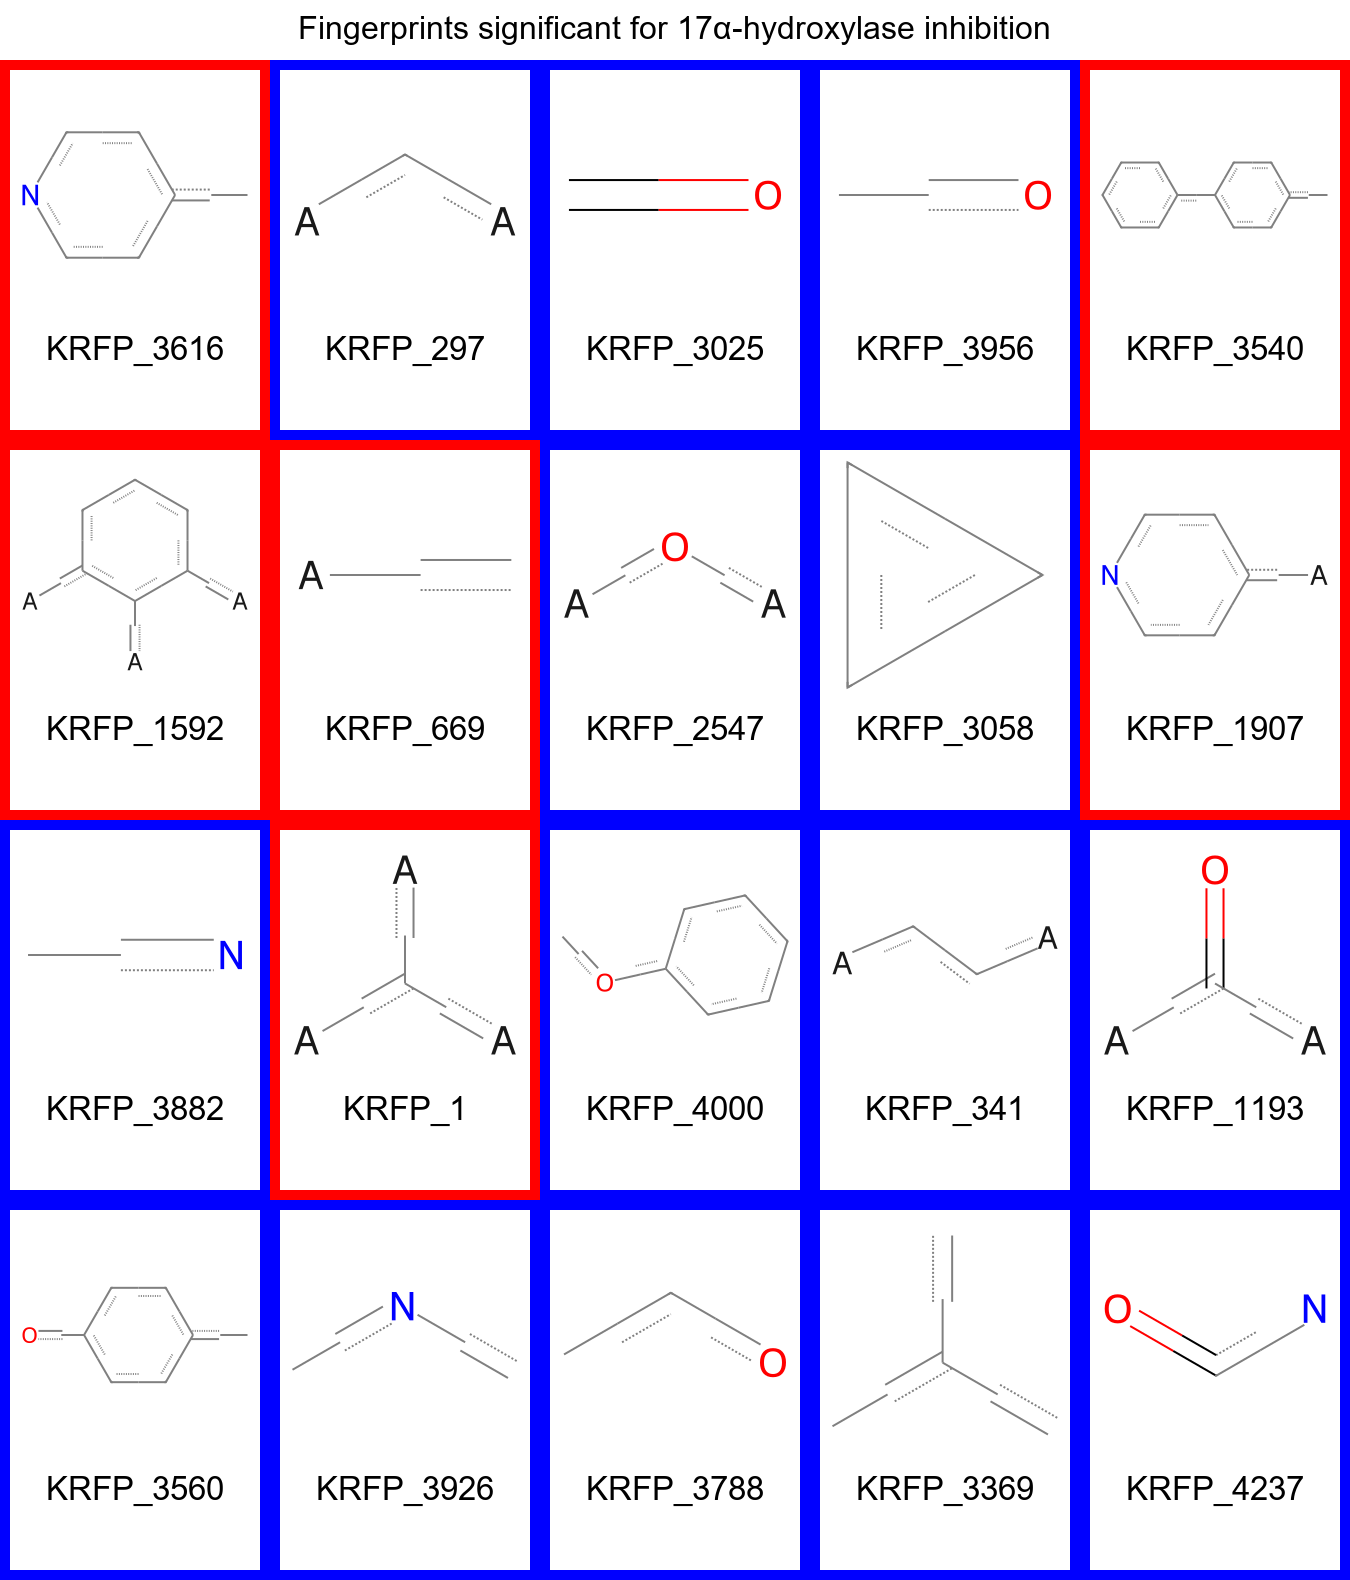

In [83]:
#HYDROXYLASE ACTIVITY KRFP
import io
import math
import json
import re
from PIL import Image, ImageOps, ImageDraw, ImageFont
from rdkit import Chem
from rdkit.Chem.Draw import rdMolDraw2D

with open("krfp.json", "r") as f:
    raw_dict = json.load(f)

krfp_dict = {
    int(re.sub(r'\D', '', k)): v for k, v in raw_dict.items()
}


selected_keys = [ 3616, 297, 3025, 3956, 3540, 1592, 669, 2547, 3058, 1907, 3882, 1, 4000, 341, 1193,3560, 3926, 3788, 3369, 4237]
red_keys = {3616, 3540, 1592, 669, 1907, 1}

blue_keys = set(selected_keys) - red_keys
def draw_fragment(smarts, title, border_color, size=(250, 360), border_width=10):
    mol_height = size[0]
    total_width = size[0]
    total_height = size[1]

    mol = Chem.MolFromSmarts(smarts)
    if mol is None:
        mol = Chem.MolFromSmarts("[H]")
    drawer = rdMolDraw2D.MolDraw2DCairo(total_width, mol_height)
    rdMolDraw2D.PrepareAndDrawMolecule(drawer, mol)
    drawer.FinishDrawing()
    mol_png = drawer.GetDrawingText()
    mol_img = Image.open(io.BytesIO(mol_png)).convert("RGB")
    final_img = Image.new("RGB", (total_width, total_height), "white")
    final_img.paste(mol_img, (0, 0))

    draw = ImageDraw.Draw(final_img)
    try:
        font = ImageFont.truetype("arial.ttf", 33)
    except:
        font = ImageFont.load_default()
    bbox = draw.textbbox((0, 0), title, font=font)
    text_w = bbox[2] - bbox[0]
    x_center = (total_width - text_w) // 2
    draw.text((x_center, mol_height + 10), title, fill="black", font=font)
    final_img = ImageOps.expand(final_img, border=border_width, fill=border_color)
    return final_img


images = []

for key in selected_keys:
    if key not in krfp_dict:
        print(f"Warning: the key {key} is absent in krfp.json")
        smarts = "[H]"
    else:
        smarts = krfp_dict[key]

    border = (255, 0, 0) if key in red_keys else (0, 0, 255)
    img = draw_fragment(smarts, f"KRFP_{key}", border)
    images.append(img)

def make_grid(images, cols=5, bg="white"):
    w, h = images[0].size
    rows = math.ceil(len(images) / cols)
    grid = Image.new("RGB", (cols * w, rows * h), bg)
    for i, im in enumerate(images):
        r, c = divmod(i, cols)
        grid.paste(im, (c * w, r * h))
    return grid

grid_img = make_grid(images, cols=5)
title_text = "Fingerprints significant for 17α-hydroxylase inhibition"

try:
    title_font = ImageFont.truetype("arial.ttf", 32)
except:
    title_font = ImageFont.load_default()

title_height = 60
W = grid_img.width
H = grid_img.height + title_height

final_img = Image.new("RGB", (W, H), "white")
draw = ImageDraw.Draw(final_img)

bbox = draw.textbbox((0, 0), title_text, font=title_font)
text_w = bbox[2] - bbox[0]
draw.text(((W - text_w) // 2, 10), title_text, fill="black", font=title_font)
final_img.paste(grid_img, (0, title_height))
final_img.save("krfp_fragments_HYDRO.tiff", dpi=(600, 600))
final_img